In [ ]:
#Allow access to google drive, where file is stored
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import scipy.io

# Define the path to the .mat file
file_path = '/content/drive/MyDrive/MMA3001/mill.mat'

# Load the .mat file
mat_data = scipy.io.loadmat(file_path)

# Display the keys available in the loaded .mat file to understand its structure
print(f"Keys in the .mat file: {mat_data.keys()}")

# You can also display a specific variable if you know its name, for example:
# if 'variable_name' in mat_data:
#     print("Content of 'variable_name':")
#     display(mat_data['variable_name'])
# else:
#     print("Consider displaying one of the keys listed above to inspect its content.")

Keys in the .mat file: dict_keys(['__header__', '__version__', '__globals__', 'mill'])


In [ ]:
if 'mill' in mat_data:
    print("Content of 'mill':")
    display(mat_data['mill'])
else:
    print("The 'mill' key was not found in the loaded MATLAB data.")

In [ ]:
import pandas as pd
import numpy as np

# Access the single record containing all the data from mat_data['mill'][0]
# This assumes mat_data['mill'] is a structured array of shape (1,)
mill_data_struct = mat_data['mill'][0]

# Get the field names from the structured data
field_names = mill_data_struct.dtype.names

# Initialize a list to hold records that will form the DataFrame
records_for_df = []

# Determine the number of primary records (e.g., number of 'case' entries).
# We assume 'case' is a reliable field to get the overall length of primary records.
num_primary_records = mill_data_struct['case'].flatten().shape[0]

# Define fields that are expected to contain time-series arrays (to be stored as arrays in DataFrame cells)
time_series_fields = ['vib_table', 'vib_spindle', 'AE_table', 'AE_spindle', 'smcAC', 'smcDC']

for i in range(num_primary_records):
    current_record = {}
    for field in field_names:
        val = mill_data_struct[field][i]
        if field in time_series_fields:
            # For time-series fields, store the actual NumPy array for this record
            if isinstance(val, np.ndarray):
                current_record[field] = val.flatten() # Store as 1D array
            else:
                # If for some reason it's not an array, store as a single-element array
                current_record[field] = np.array([val])
        else:
            # For scalar fields, extract the single value
            if isinstance(val, np.ndarray) and val.size == 1:
                current_record[field] = val.item()
            elif isinstance(val, np.ndarray):
                # If a 'scalar' field unexpectedly contains a multi-element array,
                # convert it to list or decide how to handle (e.g., take first element)
                current_record[field] = val.flatten().tolist()
            else:
                current_record[field] = val
    records_for_df.append(current_record)

# Create a Pandas DataFrame from the list of dictionaries
df_mill = pd.DataFrame(records_for_df)

# Display the first few rows of the DataFrame and its information
print("Extracted DataFrame head:")
display(df_mill.head())
print("\nDataFrame Info:")
df_mill.info()

Extracted DataFrame head:


,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,1,1,0.00,2,1.5,0.5,1,"[-0.01708984375, 0.263671875, 0.20751953125, 0...","[0.625, 0.810546875, 0.78125, 0.849609375, 1.0...","[0.078125, 0.08544921875, 0.078125, 0.07324218...","[0.31494140625, 0.301513671875, 0.303955078125...","[0.0872802734375, 0.0982666015625, 0.092163085...","[0.103759765625, 0.123291015625, 0.10498046875..."
1,1,2,NaN,4,1.5,0.5,1,"[0.3076171875, 0.3125, 0.1953125, 0.1879882812...","[0.6689453125, 0.6787109375, 0.859375, 1.12304...","[0.07568359375, 0.08056640625, 0.078125, 0.080...","[0.301513671875, 0.308837890625, 0.29907226562...","[0.086669921875, 0.0897216796875, 0.0946044921...","[0.0994873046875, 0.103759765625, 0.1080322265..."
2,1,3,NaN,6,1.5,0.5,1,"[-0.72509765625, -0.71533203125, -0.5297851562...","[0.9130859375, 0.8349609375, 0.908203125, 1.15...","[0.0830078125, 0.078125, 0.09033203125, 0.0805...","[0.29541015625, 0.296630859375, 0.29296875, 0....","[0.0927734375, 0.1007080078125, 0.093383789062...","[0.10498046875, 0.1190185546875, 0.10986328125..."
3,1,4,0.11,7,1.5,0.5,1,"[0.1123046875, 0.009765625, -0.1513671875, -0....","[0.1318359375, 0.3955078125, 0.7568359375, 0.8...","[0.0830078125, 0.07568359375, 0.06591796875, 0...","[0.316162109375, 0.311279296875, 0.302734375, ...","[0.1129150390625, 0.0994873046875, 0.104980468...","[0.1397705078125, 0.1214599609375, 0.124511718..."
4,1,5,NaN,11,1.5,0.5,1,"[-0.1220703125, -0.16357421875, -0.36865234375...","[0.44921875, 0.6640625, 0.6689453125, 0.747070...","[0.107421875, 0.107421875, 0.1025390625, 0.100...","[0.284423828125, 0.289306640625, 0.28442382812...","[0.0958251953125, 0.09765625, 0.09765625, 0.09...","[0.1104736328125, 0.113525390625, 0.1098632812..."



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   case         167 non-null    int64  
 1   run          167 non-null    int64  
 2   VB           146 non-null    float64
 3   time         167 non-null    int64  
 4   DOC          167 non-null    float64
 5   feed         167 non-null    float64
 6   material     167 non-null    int64  
 7   smcAC        167 non-null    object 
 8   smcDC        167 non-null    object 
 9   vib_table    167 non-null    object 
 10  vib_spindle  167 non-null    object 
 11  AE_table     167 non-null    object 
 12  AE_spindle   167 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 17.1+ KB


In [ ]:
# Drop rows where 'VB' is NaN
df_mill_cleaned = df_mill.dropna(subset=['VB']).copy()

print("DataFrame head after dropping rows with NaN in 'VB':")
display(df_mill_cleaned.head())
print("\nDataFrame Info after dropping rows with NaN in 'VB':")
df_mill_cleaned.info()

DataFrame head after dropping rows with NaN in 'VB':


,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,1,1,0.00,2,1.5,0.5,1,"[-0.01708984375, 0.263671875, 0.20751953125, 0...","[0.625, 0.810546875, 0.78125, 0.849609375, 1.0...","[0.078125, 0.08544921875, 0.078125, 0.07324218...","[0.31494140625, 0.301513671875, 0.303955078125...","[0.0872802734375, 0.0982666015625, 0.092163085...","[0.103759765625, 0.123291015625, 0.10498046875..."
3,1,4,0.11,7,1.5,0.5,1,"[0.1123046875, 0.009765625, -0.1513671875, -0....","[0.1318359375, 0.3955078125, 0.7568359375, 0.8...","[0.0830078125, 0.07568359375, 0.06591796875, 0...","[0.316162109375, 0.311279296875, 0.302734375, ...","[0.1129150390625, 0.0994873046875, 0.104980468...","[0.1397705078125, 0.1214599609375, 0.124511718..."
5,1,6,0.20,15,1.5,0.5,1,"[0.32958984375, 0.3076171875, 0.27099609375, 0...","[0.68359375, 0.87890625, 0.83984375, 0.9033203...","[0.07080078125, 0.0732421875, 0.0732421875, 0....","[0.3076171875, 0.31005859375, 0.306396484375, ...","[0.103759765625, 0.0927734375, 0.089111328125,...","[0.1202392578125, 0.1068115234375, 0.09765625,..."
6,1,7,0.24,19,1.5,0.5,1,"[-0.57861328125, -0.58349609375, -0.5224609375...","[1.3818359375, 1.396484375, 1.40625, 1.4208984...","[0.06591796875, 0.06591796875, 0.068359375, 0....","[0.322265625, 0.299072265625, 0.313720703125, ...","[0.0909423828125, 0.0726318359375, 0.082397460...","[0.1239013671875, 0.101318359375, 0.1116943359..."
7,1,8,0.29,22,1.5,0.5,1,"[0.30029296875, 0.25634765625, 0.1708984375, 0...","[1.435546875, 1.4404296875, 1.4453125, 1.44531...","[0.06103515625, 0.06591796875, 0.06103515625, ...","[0.308837890625, 0.303955078125, 0.30639648437...","[0.0927734375, 0.0994873046875, 0.09765625, 0....","[0.108642578125, 0.12451171875, 0.114135742187..."



DataFrame Info after dropping rows with NaN in 'VB':
<class 'pandas.core.frame.DataFrame'>
Index: 146 entries, 0 to 166
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   case         146 non-null    int64  
 1   run          146 non-null    int64  
 2   VB           146 non-null    float64
 3   time         146 non-null    int64  
 4   DOC          146 non-null    float64
 5   feed         146 non-null    float64
 6   material     146 non-null    int64  
 7   smcAC        146 non-null    object 
 8   smcDC        146 non-null    object 
 9   vib_table    146 non-null    object 
 10  vib_spindle  146 non-null    object 
 11  AE_table     146 non-null    object 
 12  AE_spindle   146 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 16.0+ KB


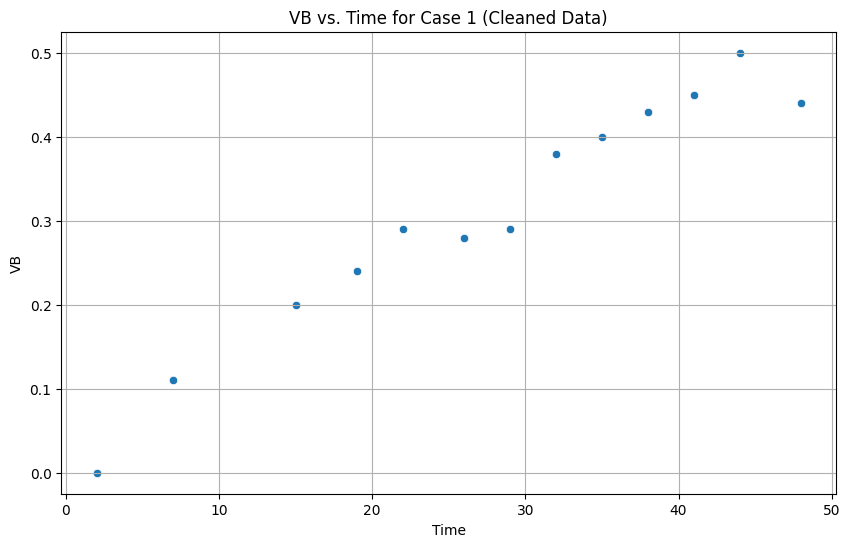

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the cleaned DataFrame for case 1
df_case_1 = df_mill_cleaned[df_mill_cleaned['case'] == 1]

# Create the plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='time', y='VB', data=df_case_1)
plt.title('VB vs. Time for Case 1 (Cleaned Data)')
plt.xlabel('Time')
plt.ylabel('VB')
plt.grid(True)
plt.show()

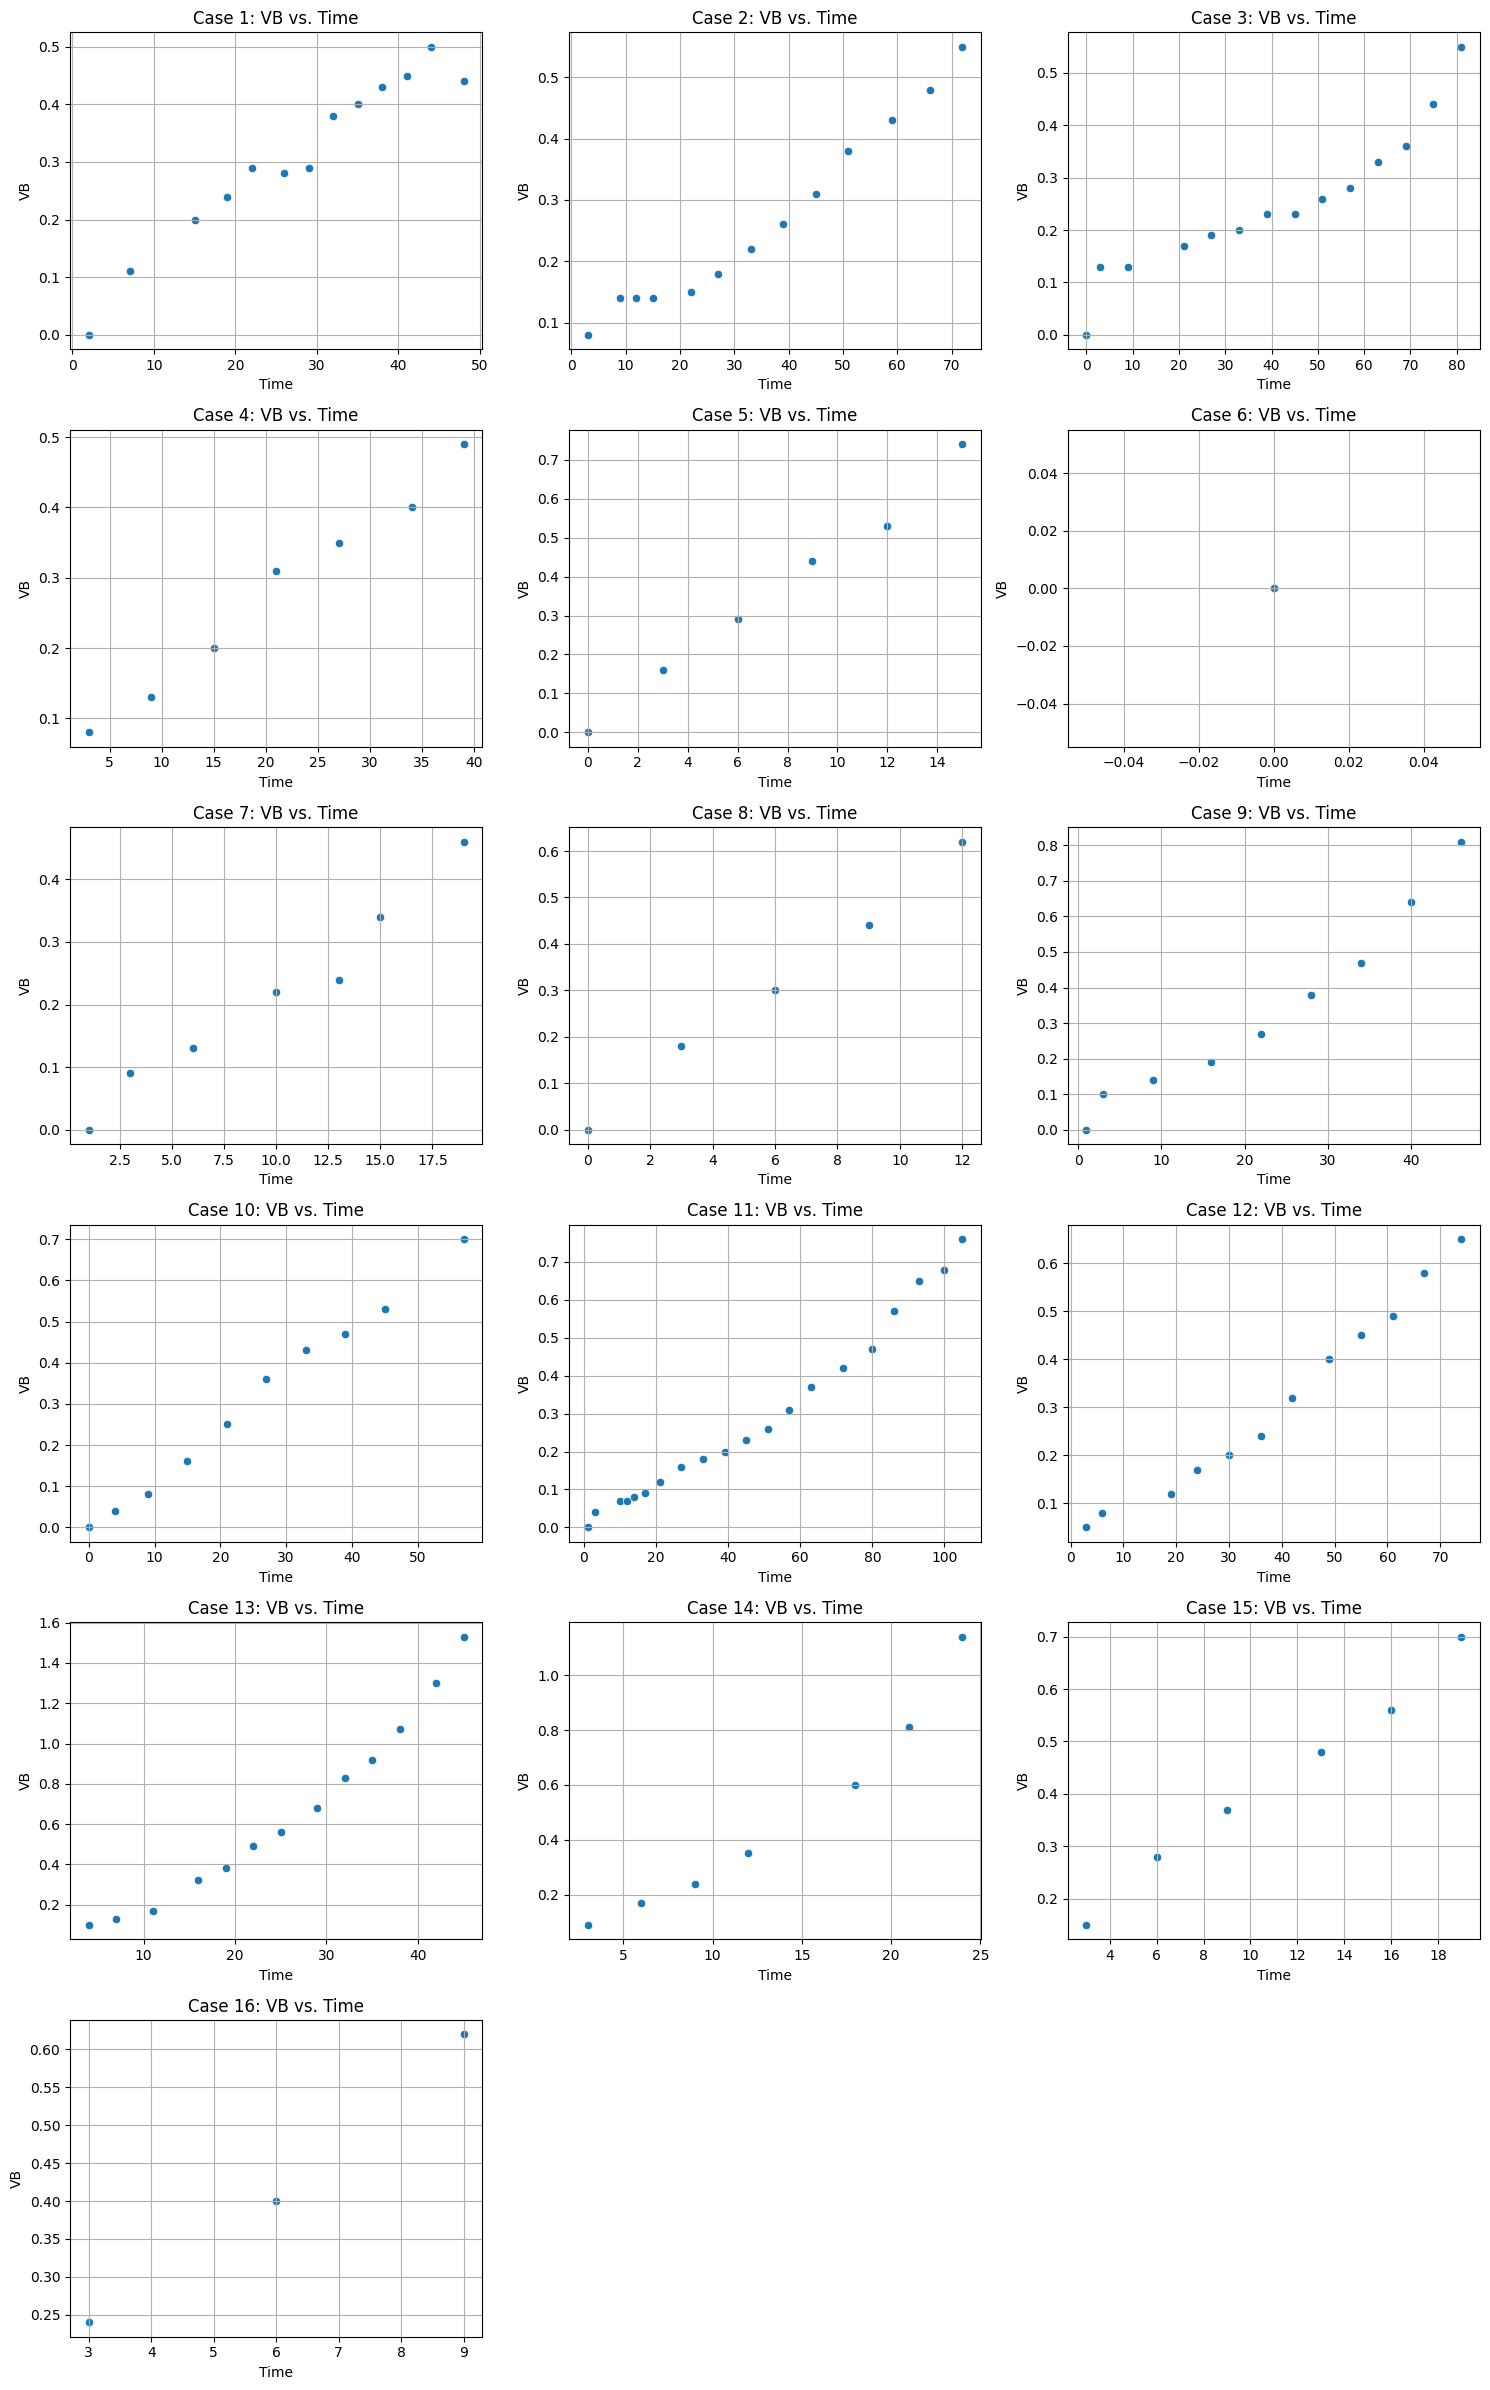

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Get all unique cases
unique_cases = df_mill_cleaned['case'].unique()
unique_cases.sort() # Sort for consistent plotting order

# Determine the number of rows and columns for subplots
num_cases = len(unique_cases)
cols = 3 # You can adjust this number
rows = math.ceil(num_cases / cols)

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), squeeze=False)
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, case_num in enumerate(unique_cases):
    ax = axes[i]
    df_current_case = df_mill_cleaned[df_mill_cleaned['case'] == case_num]

    sns.scatterplot(x='time', y='VB', data=df_current_case, ax=ax)
    ax.set_title(f'Case {case_num}: VB vs. Time')
    ax.set_xlabel('Time')
    ax.set_ylabel('VB')
    ax.grid(True)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
case_counts = df_mill_cleaned.groupby('case').size()
cases_to_remove = case_counts[case_counts == 1].index.tolist()

print(f"Cases with only one data entry to be removed: {cases_to_remove}")

df_mill_filtered = df_mill_cleaned[~df_mill_cleaned['case'].isin(cases_to_remove)].copy()

Cases with only one data entry to be removed: [6]


In [ ]:
print("DataFrame head after removing cases with only one data entry:")
display(df_mill_filtered.head())
print("\nDataFrame Info after removing cases with only one data entry:")
df_mill_filtered.info()

DataFrame head after removing cases with only one data entry:


,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,1,1,0.00,2,1.5,0.5,1,"[-0.01708984375, 0.263671875, 0.20751953125, 0...","[0.625, 0.810546875, 0.78125, 0.849609375, 1.0...","[0.078125, 0.08544921875, 0.078125, 0.07324218...","[0.31494140625, 0.301513671875, 0.303955078125...","[0.0872802734375, 0.0982666015625, 0.092163085...","[0.103759765625, 0.123291015625, 0.10498046875..."
3,1,4,0.11,7,1.5,0.5,1,"[0.1123046875, 0.009765625, -0.1513671875, -0....","[0.1318359375, 0.3955078125, 0.7568359375, 0.8...","[0.0830078125, 0.07568359375, 0.06591796875, 0...","[0.316162109375, 0.311279296875, 0.302734375, ...","[0.1129150390625, 0.0994873046875, 0.104980468...","[0.1397705078125, 0.1214599609375, 0.124511718..."
5,1,6,0.20,15,1.5,0.5,1,"[0.32958984375, 0.3076171875, 0.27099609375, 0...","[0.68359375, 0.87890625, 0.83984375, 0.9033203...","[0.07080078125, 0.0732421875, 0.0732421875, 0....","[0.3076171875, 0.31005859375, 0.306396484375, ...","[0.103759765625, 0.0927734375, 0.089111328125,...","[0.1202392578125, 0.1068115234375, 0.09765625,..."
6,1,7,0.24,19,1.5,0.5,1,"[-0.57861328125, -0.58349609375, -0.5224609375...","[1.3818359375, 1.396484375, 1.40625, 1.4208984...","[0.06591796875, 0.06591796875, 0.068359375, 0....","[0.322265625, 0.299072265625, 0.313720703125, ...","[0.0909423828125, 0.0726318359375, 0.082397460...","[0.1239013671875, 0.101318359375, 0.1116943359..."
7,1,8,0.29,22,1.5,0.5,1,"[0.30029296875, 0.25634765625, 0.1708984375, 0...","[1.435546875, 1.4404296875, 1.4453125, 1.44531...","[0.06103515625, 0.06591796875, 0.06103515625, ...","[0.308837890625, 0.303955078125, 0.30639648437...","[0.0927734375, 0.0994873046875, 0.09765625, 0....","[0.108642578125, 0.12451171875, 0.114135742187..."



DataFrame Info after removing cases with only one data entry:
<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 0 to 166
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   case         145 non-null    int64  
 1   run          145 non-null    int64  
 2   VB           145 non-null    float64
 3   time         145 non-null    int64  
 4   DOC          145 non-null    float64
 5   feed         145 non-null    float64
 6   material     145 non-null    int64  
 7   smcAC        145 non-null    object 
 8   smcDC        145 non-null    object 
 9   vib_table    145 non-null    object 
 10  vib_spindle  145 non-null    object 
 11  AE_table     145 non-null    object 
 12  AE_spindle   145 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 15.9+ KB
